# 01 · 真实资产与数字孪生

使用 laptop1 的 RGB-D、Mask 与 USD，完成相机恢复、深度增强、铰接重建、配准、质量评估与导出。

**流程**：输入 → 相机与尺度 → RGB-D → 重建 → 配准 → 评估 → 导出。


## 1. 输入与环境

检查运行环境并导入实拍数据与参考 USD。


In [1]:
import io
import json
import zipfile
from collections import Counter

from examples._display import (
    setup_notebook,
    show_animation,
    show_metrics,
    show_reconstruction_evaluation,
    show_rgbd,
)

PROJECT_ROOT, OUTPUT_DIR = setup_notebook("real_assets_and_digital_twin")

from physrealx import ArtifactRef, MethodCapability, PhysRealX, ReconstructionEvaluationInput
from physrealx.integrations.registration import ReferenceRegistrationInput
from physrealx.integrations.rgbd import MetricRGBDInput
from physrealx.integrations.usd_reference import evaluate_reference_kinematics

px = PhysRealX.open(PROJECT_ROOT / ".physrealx")
for capability, method in (
    (MethodCapability.CAMERA_RECOVER, "colmap"),
    (MethodCapability.CAMERA_ALIGN_METRIC, "usd_depth_scale"),
    (MethodCapability.DEPTH_ENHANCE, "rgb_guided_fill"),
    (MethodCapability.GEOMETRY_RECONSTRUCT, "artgs"),
    (MethodCapability.CAMERA_ALIGN_METRIC, "articulated_surface_icp"),
):
    status = px.methods.inspect(capability, method)
    if not status.ready:
        raise RuntimeError(f"{method}: {status.detail}")


Python,3.11.15
解释器,/home/yxp/miniconda3/envs/PhysReal-X/bin/python


In [2]:
inspection = px.assets.inspect_source(
    PROJECT_ROOT / "examples/real_assets_and_digital_twin/input/ArtModeling/laptop1",
    importer="artmodeling",
    config={"states": ["can.start", "can.end"]},
)
if not inspection.ingestible:
    raise RuntimeError("ArtModeling 数据包未通过结构预检。")
observations = px.assets.ingest(
    PROJECT_ROOT / "examples/real_assets_and_digital_twin/input/ArtModeling/laptop1",
    resource_id="laptop1.observations",
    version="4.0.0",
    display_name="Laptop 1 captures and reverse-engineered USD",
    importer="artmodeling",
    config={
        "states": ["can.start", "can.end"],
        "depth_unit": "native_u16_unscaled",
        "coordinate_frame": "camera_unregistered",
        "include_candidates": True,
        "view_alignment": {
            "can.start.rgb": {
                "mode": "fiducial_assisted",
                "fiducial": {"family": "aruco_6x6_50", "layout_id": "laptop1.table.markers"},
            },
            "can.end.rgb": {
                "mode": "fiducial_assisted",
                "fiducial": {"family": "aruco_6x6_50", "layout_id": "laptop1.table.markers"},
            },
        },
    },
)
reference_model = px.assets.import_reference(
    observations,
    usd_path="sim/usd/model_laptop.usd",
    root_link="body",
    moving_links=("cover",),
)
reference = json.loads(px.artifacts.get_bytes(reference_model))
show_metrics(
    {
        "采集流": len(inspection.streams),
        "USD 部件": len(reference["links"]),
        "活动关节": len(reference["joints"]),
        "来源冲突 (已记录)": len(reference["metadata_conflicts"]),
    }
)


采集流,6
USD 部件,2
活动关节,1
来源冲突 (已记录),0


## 2. 相机与米制尺度

恢复双状态相机并对齐米制尺度。


In [3]:
camera_operation = px.assets.recover_cameras(
    observations,
    method="colmap",
    config={
        "execution_device": "cpu",
        "matching": "sequential",
        "max_frames_per_stream": None,
        "min_registered_images": 150,
        "stream_names": ["can.start.rgb", "can.end.rgb"],
        "num_threads": 1,
        "random_seed": 0,
    },
)
camera_rig = camera_operation.output("camera_rig_calibration")
observation_artifact = ArtifactRef(
    artifact_id=observations.artifact_id,
    size_bytes=len(px.artifacts.get_bytes(observations.artifact_id)),
    media_type="application/vnd.physrealx.observation-set+json",
)
scale_input = px.artifacts.put_json(
    {
        "schema": "physrealx.model-scale-input/1",
        "observations": observation_artifact.model_dump(mode="json"),
        "reference_model": reference_model.model_dump(mode="json"),
    }
)
metric_operation = px.assets.align_cameras_metric(
    camera_rig, scale_input, method="usd_depth_scale", config={}
)
metric_camera = metric_operation.output("camera_rig_calibration")
show_metrics(
    {
        "注册视角": int(camera_operation.metrics["registered_image_count"]),
        "重投影误差 (px)": camera_operation.metrics["mean_reprojection_error_px"],
        "高度验证相对误差": metric_operation.metrics["max_height_holdout_relative_error"],
    }
)


注册视角,752
重投影误差 (px),0.6668
高度验证相对误差,0.04517


## 3. RGB-D 与深度增强

绑定 RGB、Depth、Mask 与相机，并增强有效深度。


数据集 Mask 帧,752
自监督 RMSE (m),0.001314


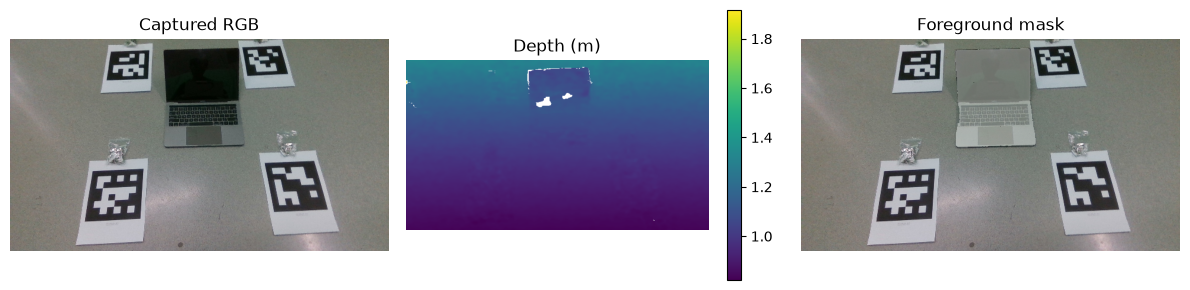

In [4]:
import numpy as np

calibrated_rgbd = px.assets.prepare_rgbd(
    observations,
    metric_camera,
    stride=2,
    max_frames_per_stream=None,
)
depth_operation = px.assets.enhance_depth(
    calibrated_rgbd, method="rgb_guided_fill", config={"max_rmse_m": 0.02}
)
enhanced_depth = depth_operation.output("enhanced_depth")
rgbd_input = MetricRGBDInput(
    camera_rig=metric_camera, enhanced_depth=enhanced_depth, reference_model=reference_model
)
geometry_input = px.artifacts.put_json(rgbd_input)
show_metrics(
    {
        "数据集 Mask 帧": len(json.loads(px.artifacts.get_bytes(calibrated_rgbd))["frames"]),
        "自监督 RMSE (m)": depth_operation.metrics["holdout_rmse_m"],
    }
)
with zipfile.ZipFile(io.BytesIO(px.artifacts.get_bytes(enhanced_depth))) as archive:
    first = json.loads(archive.read("manifest.json"))["frames"][0]
    depth_image = np.load(io.BytesIO(archive.read(first["depth"]["path"])), allow_pickle=False)
    rgb_image = np.load(
        io.BytesIO(px.artifacts.get_bytes(ArtifactRef.model_validate(first["rgb"]))),
        allow_pickle=False,
    )
    foreground_mask = np.load(
        io.BytesIO(
            px.artifacts.get_bytes(ArtifactRef.model_validate(first["view"]["object_mask"]))
        ),
        allow_pickle=False,
    )
show_rgbd(
    rgb_image, depth_image, OUTPUT_DIR / "rgbd-preview.png", mask=foreground_mask
)


## 4. 几何与关节重建

每状态使用 100 张训练图和 50 张验证图，重建部件几何与关节运动。


In [5]:
reconstruction_operation = px.assets.reconstruct_geometry(
    geometry_input,
    method="artgs",
    config={
        "num_slots": 2,
        "state_streams": ["can.start.rgb", "can.end.rgb"],
        "reference_joint": "cover.joint",
        "training_frames_per_state": 100,
        "seed": 2026,
        "max_stage_seconds": 14400,
    },
)
reconstruction_report_ref = reconstruction_operation.output("geometry_reconstruction_report")
reconstruction_report = json.loads(px.artifacts.get_bytes(reconstruction_report_ref))
assert reconstruction_report["evaluation_scope"] == "held_out_views"
assert reconstruction_report["motion_group_count"] == 2
training_counts = Counter(
    frame.rsplit(".", 1)[0] for frame in reconstruction_report["training_frame_ids"]
)
validation_counts = Counter(
    frame.rsplit(".", 1)[0] for frame in reconstruction_report["validation_frame_ids"]
)
assert training_counts == {"can.start.rgb": 100, "can.end.rgb": 100}
assert validation_counts == {"can.start.rgb": 50, "can.end.rgb": 50}
show_metrics({f"{state} / 训练": count for state, count in training_counts.items()})
show_metrics({f"{state} / 验证": count for state, count in validation_counts.items()})
show_metrics({"运动组": reconstruction_report["motion_group_count"]})
reconstruction_bundle = reconstruction_operation.output("visual_geometry_bundle")


can.start.rgb / 训练,100
can.end.rgb / 训练,100


can.start.rgb / 验证,50
can.end.rgb / 验证,50


运动组,2


## 5. 位姿绑定与关节校核

将重建结果与参考 USD 配准，并校核关节构型。


In [6]:
registration_input = px.artifacts.put_json(
    ReferenceRegistrationInput(rgbd=rgbd_input, reconstruction_report=reconstruction_report_ref)
)
registration_operation = px.assets.align_cameras_metric(
    metric_camera,
    registration_input,
    method="articulated_surface_icp",
    config={"joint": "cover.joint"},
)
reference_registration = registration_operation.output("metric_alignment_report")
reference_registration_report = json.loads(px.artifacts.get_bytes(reference_registration))
assert reference_registration_report["fit_stage"] == "pre_reconstruction"
assert reference_registration_report["gates"]["reference_guided_training"] is True
registered_cameras = registration_operation.output("camera_rig_calibration")
joint_positions_closed = {joint["name"]: joint["lower_limit"] for joint in reference["joints"]}
joint_positions_open = {joint["name"]: joint["upper_limit"] for joint in reference["joints"]}
closed_kinematics = evaluate_reference_kinematics(
    reference_model, px.artifacts, joint_positions_closed
)
open_kinematics = evaluate_reference_kinematics(reference_model, px.artifacts, joint_positions_open)
show_metrics(
    {
        "验证视图最大中位距离 (mm)": registration_operation.metrics["max_holdout_median_m"] * 1000,
        "验证视图最大 P90 距离 (mm)": registration_operation.metrics["max_holdout_p90_m"] * 1000,
        "校核关节数": len(reference["joints"]),
    }
)


验证视图最大中位距离 (mm),5.167
验证视图最大 P90 距离 (mm),16.27
校核关节数,1


## 6. 重建质量评估

计算部件、静态结构、整体几何及关节指标，并展示重建与参考动画。


几何,起始 CD (10⁻³ m²),运动后 CD (10⁻³ m²),范围 / 状态
CD-w：整体,0.21045,2.3413,协议过滤后的重建表面与全部参考表面
CD-s：静态组合,0.2664,0.2664,机身
屏幕,0.5894,4.2602,已评估


关节,类型,Axis Ang (°),Axis Pos (10⁻¹ m),Part Motion,运动单位,状态
屏幕关节,旋转,0.50002,0.31055,22.687,deg,已评估


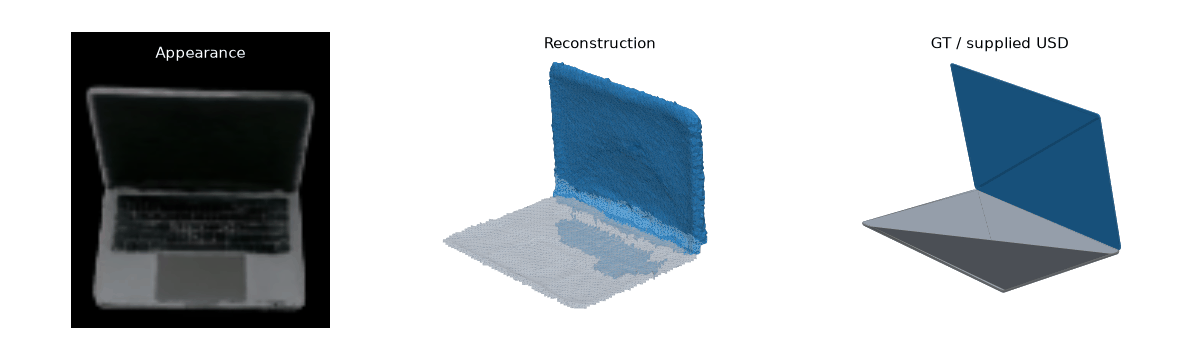

In [7]:
reconstruction_evaluation_ref = px.assets.evaluate_reconstruction(
    px.artifacts.put_json(
        ReconstructionEvaluationInput(
            reconstruction_report=reconstruction_report_ref,
            reference_model=reference_model,
            registration=reference_registration,
            joint_names=("cover.joint",),
        )
    ),
)
show_reconstruction_evaluation(
    json.loads(px.artifacts.get_bytes(reconstruction_evaluation_ref)),
    labels={"body": "机身", "cover": "屏幕"},
)
reconstruction_animation = px.assets.preview_reconstruction(reconstruction_evaluation_ref)
show_animation(px.artifacts.get_bytes(reconstruction_animation))


## 7. 结果导出

导出下游模块所需的标准制品与结果索引。


In [8]:
exports = {
    "reference-model.json": reference_model,
    "reference-usd.zip": ArtifactRef.model_validate(reference["bundle"]),
    "reference-registration.json": reference_registration,
    "registered-cameras.json": registered_cameras,
    "metric-cameras.json": metric_camera,
    "calibrated-rgbd.json": calibrated_rgbd,
    "enhanced-depth.zip": enhanced_depth,
    "reconstruction-input.json": geometry_input,
    "reconstruction.zip": reconstruction_bundle,
    "reconstruction-report.json": reconstruction_report_ref,
    "reconstruction-evaluation.json": reconstruction_evaluation_ref,
    "reconstruction-comparison.gif": reconstruction_animation,
    "kinematics-closed.json": closed_kinematics,
    "kinematics-open.json": open_kinematics,
}
results = {name: ref.model_dump(mode="json") for name, ref in exports.items()}
results_ref = px.artifacts.export(OUTPUT_DIR, results, files=exports)
print("结果索引:", OUTPUT_DIR / "results.json")


结果索引: /mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/examples/real_assets_and_digital_twin/output/results.json
